## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Data Loading

In [2]:
DATA_PATH = Path("Unemployment in India.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}\n"
                            "Place 'Unemployment in India.csv' in the same folder as this notebook."
                           )

raw_df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")
display(raw_df.head())

Dataset loaded successfully.


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 3. Shape Inspection

In [3]:
print("Dataset Shape:", raw_df.shape)
print("Total Rows:", raw_df.shape[0])
print("Total Columns:", raw_df.shape[1])

print("\nColumn Names:")
print(raw_df.columns.tolist())

print("\nDataset Information:")
raw_df.info()

print("\nStatistical Summary:")
display(raw_df.describe(include="all").T)

Dataset Shape: (768, 7)
Total Rows: 768
Total Columns: 7

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
me

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,740,28,Andhra Pradesh,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,740,14,31-10-2019,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency,740,2,Monthly,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),740.0,NaN,NaN,NaN,11.787946,10.721298,0.0,4.6575,8.35,15.8875,76.74
Estimated Employed,740.0,NaN,NaN,NaN,7204460.025676,8087988.429458,49420.0,1190404.5,4744178.5,11275489.5,45777509.0
Estimated Labour Participation Rate (%),740.0,NaN,NaN,NaN,42.630122,8.111094,13.33,38.0625,41.16,45.505,72.57
Area,740,2,Urban,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Null Value and Duplicate Check

In [4]:
print("Missing values in each column:")
display(raw_df.isnull().sum().to_frame("Missing Values"))

print("Total missing cells:", raw_df.isnull().sum().sum())
print("Duplicate rows:", raw_df.duplicated().sum())

Missing values in each column:


,Missing Values
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


Total missing cells: 196
Duplicate rows: 27


## 5. Data Cleaning and Type Conversion

In [5]:
df = raw_df.copy()

# Remove extra spaces from column names and text values
df.columns = df.columns.astype(str).str.strip()

for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].apply(lambda value: value.strip() if isinstance(value, str) else value)

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", dayfirst=True)

# Convert numerical columns
numeric_columns = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows missing required analysis fields
required_columns = ["Region", "Date"] + numeric_columns
df = df.dropna(subset=required_columns)

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Create month column for monthly analysis
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df = df.sort_values(["Region", "Date"]).reset_index(drop=True)
print("Cleaning completed.")
print("Cleaned Shape:", df.shape)
print("Missing values after cleaning:", df.isnull().sum().sum())
display(df.head())

Cleaning completed.
Cleaned Shape: (740, 8)
Missing values after cleaning: 0


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Month
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019-05-01
1,Andhra Pradesh,2019-05-31,Monthly,6.09,4788661.0,37.45,Urban,2019-05-01
2,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,2019-06-01
3,Andhra Pradesh,2019-06-30,Monthly,3.80,4824630.0,36.76,Urban,2019-06-01
4,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,2019-07-01


### Markdown Observation 1 – Data Cleaning
- The original dataset contains blank or incomplete records.
- Column names and text values are standardized by removing extra spaces.
- The `Date` column is converted to datetime format.
- The unemployment rate, estimated employed count and labour participation rate are converted to numeric data types.
- Rows missing required analysis fields and duplicate rows are removed.
- A `Month` column is created for monthly trend analysis.

## 6. Region-wise Average Unemployment Rate

,Region,Estimated Unemployment Rate (%)
24,Tripura,28.350357
8,Haryana,26.283214
11,Jharkhand,20.585000
2,Bihar,18.918214
9,Himachal Pradesh,18.540357
5,Delhi,16.495357
10,Jammu & Kashmir,16.188571
3,Chandigarh,15.991667
20,Rajasthan,14.058214
25,Uttar Pradesh,12.551429


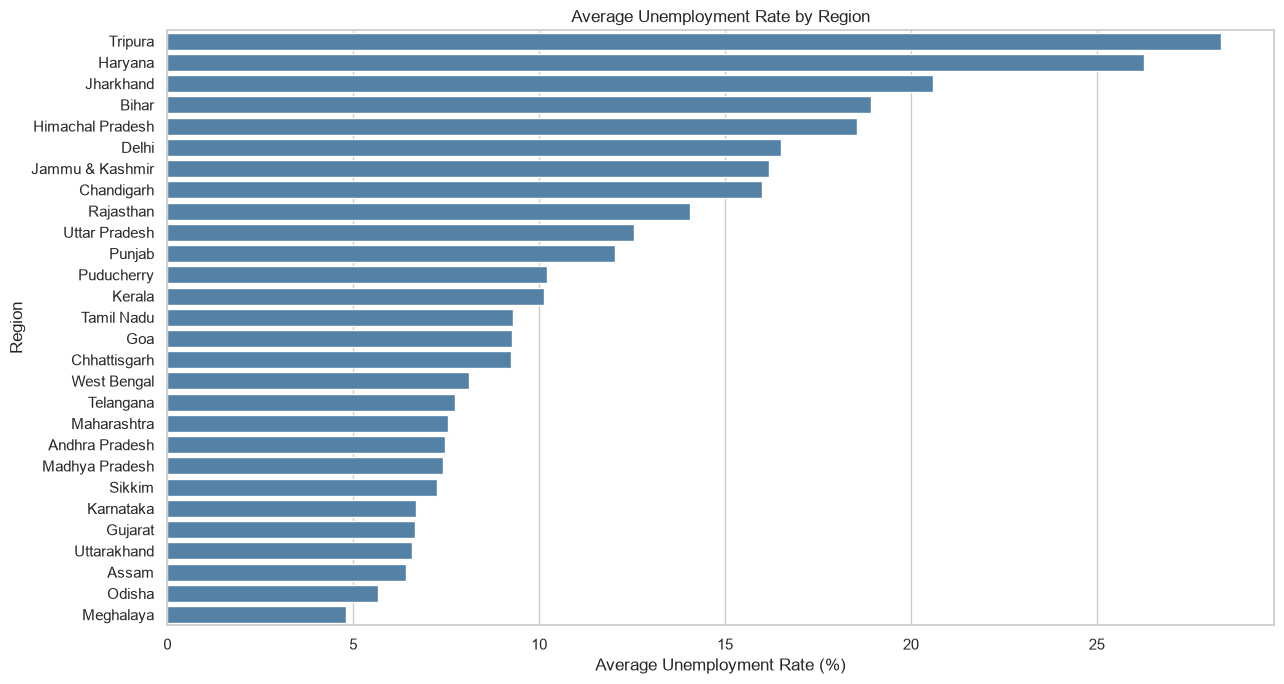

In [6]:
region_avg = (df.groupby("Region", as_index=False)["Estimated Unemployment Rate (%)"].mean().sort_values("Estimated Unemployment Rate (%)", ascending=False))
display(region_avg.head(10))
plt.figure(figsize=(13, 7))
sns.barplot(data=region_avg, x="Estimated Unemployment Rate (%)", y="Region", color="steelblue")
plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### Markdown Observation 2 – Region-wise Analysis
- Average unemployment rates differ across regions.
- Regions at the top of the chart have higher average unemployment rates during the period covered by the dataset.
- Regional averages help identify locations that may need closer employment-related attention.
- These values describe the dataset period and should not be interpreted as current unemployment rates.

## 7. Month-wise Unemployment Trend

,Month,Estimated Unemployment Rate (%)
0,2019-05-01,8.874259
1,2019-06-01,9.303333
2,2019-07-01,9.033889
3,2019-08-01,9.637925
4,2019-09-01,9.051731
5,2019-10-01,9.900909
6,2019-11-01,9.868364
7,2019-12-01,9.497358
8,2020-01-01,9.950755
9,2020-02-01,9.964717


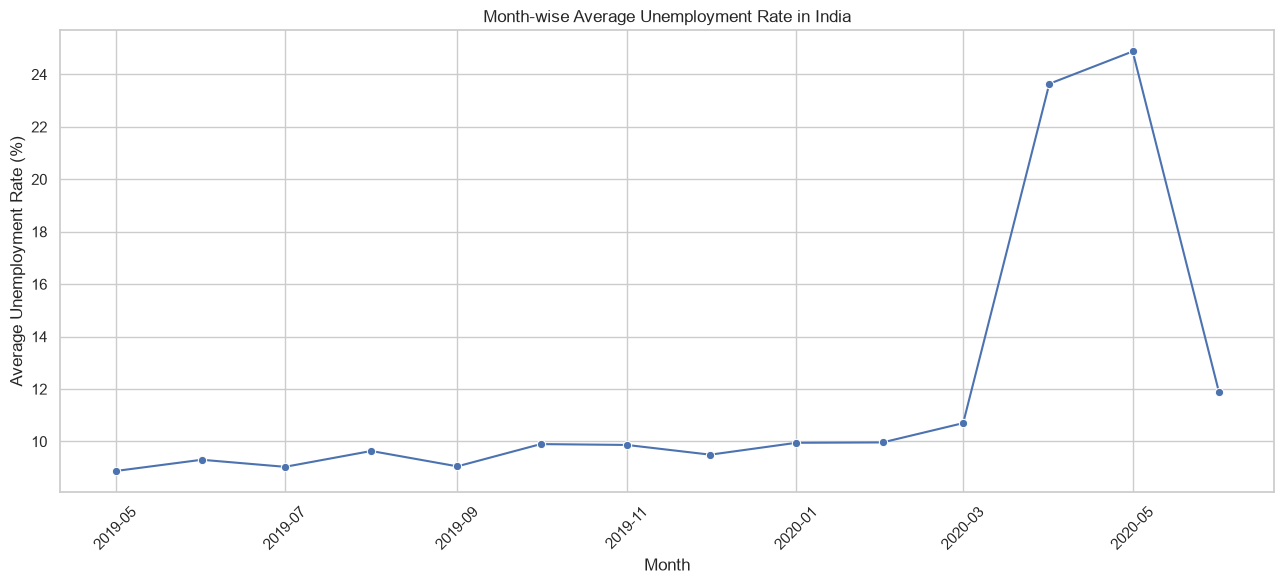

In [7]:
monthly_avg = (df.groupby("Month", as_index=False)["Estimated Unemployment Rate (%)"].mean().sort_values("Month"))
display(monthly_avg)
plt.figure(figsize=(13, 6))
sns.lineplot(data=monthly_avg, x="Month", y="Estimated Unemployment Rate (%)", marker="o")
plt.title("Month-wise Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Markdown Observation 3 – Month-wise Trends
- The monthly line chart shows how the average unemployment rate changes over time.
- Peaks indicate months with higher average unemployment, while declines indicate lower averages.
- Monthly aggregation makes the overall time pattern easier to understand than daily-level records.
- The observed trend is limited to the dates available in this dataset.

## 8. Three-State Combined Time-Series Chart

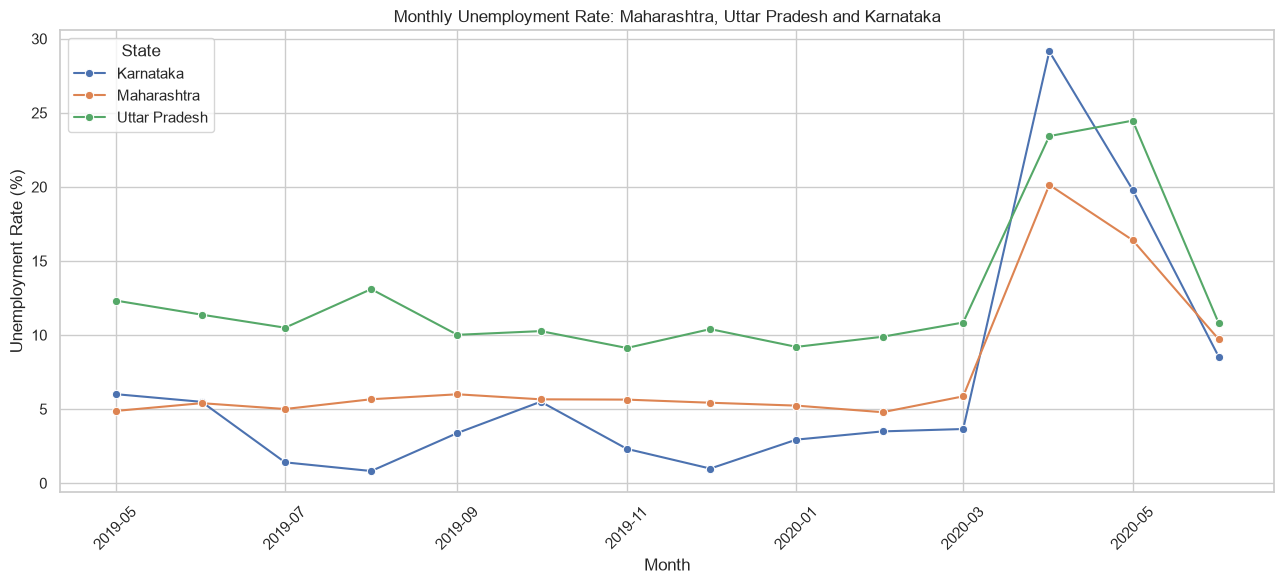

In [8]:
selected_states = ["Maharashtra", "Uttar Pradesh", "Karnataka"]
available_states = df["Region"].dropna().unique().tolist()
states_to_plot = [state for state in selected_states if state in available_states]

if len(states_to_plot) < 3:
    print("Warning: Fewer than three requested states are available.")
    print("Available selected states:", states_to_plot)
else:
    state_monthly = (df[df["Region"].isin(states_to_plot)].groupby(["Month", "Region"], as_index=False)["Estimated Unemployment Rate (%)"].mean())
    plt.figure(figsize=(13, 6))
    sns.lineplot(data=state_monthly, x="Month", y="Estimated Unemployment Rate (%)", hue="Region", marker="o")
    plt.title("Monthly Unemployment Rate: Maharashtra, Uttar Pradesh and Karnataka")
    plt.xlabel("Month")
    plt.ylabel("Unemployment Rate (%)")
    plt.xticks(rotation=45)
    plt.legend(title="State")
    plt.tight_layout()
    plt.show()

### Markdown Observation 4 – Three-State Comparison
- The combined chart compares monthly unemployment-rate movement across Maharashtra, Uttar Pradesh and Karnataka, when all three are present in the dataset.
- The lines make it possible to compare timing and direction of changes across the selected states.
- Differences between the lines indicate that unemployment trends are not identical across regions.
- The chart represents only the selected states and the dataset's available time period.

## 9. Top 10 Regions with Highest Average Unemployment

,Region,Estimated Unemployment Rate (%)
24,Tripura,28.350357
8,Haryana,26.283214
11,Jharkhand,20.585000
2,Bihar,18.918214
9,Himachal Pradesh,18.540357
5,Delhi,16.495357
10,Jammu & Kashmir,16.188571
3,Chandigarh,15.991667
20,Rajasthan,14.058214
25,Uttar Pradesh,12.551429


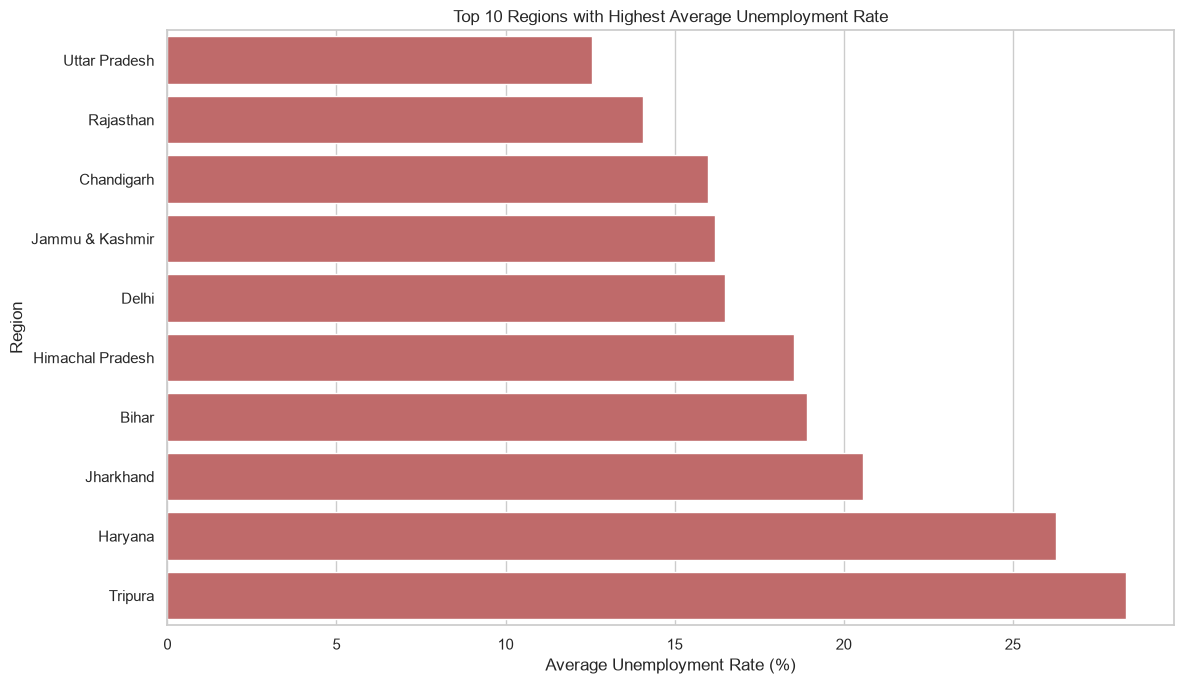

In [9]:
top_10_regions = region_avg.head(10).sort_values("Estimated Unemployment Rate (%)", ascending=True)
display(top_10_regions.sort_values("Estimated Unemployment Rate (%)", ascending=False))
plt.figure(figsize=(12, 7))
sns.barplot(data=top_10_regions, x="Estimated Unemployment Rate (%)", y="Region", color="indianred")
plt.title("Top 10 Regions with Highest Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### Markdown Observation 5 – Top 10 Regions
- The bar chart ranks the ten regions with the highest average unemployment rate in the cleaned dataset.
- The longest bar represents the highest regional average among the ten selected regions.
- This ranking helps focus attention on regions with comparatively higher unemployment in the observed period.
- It is a historical comparison, not a statement about present-day rankings.

## 10. Correlation Heatmap – Employment Count

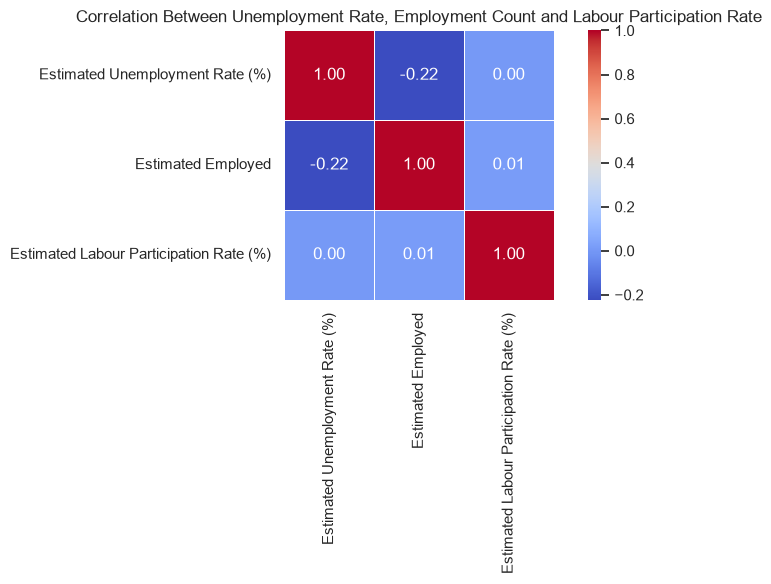

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


In [10]:
correlation_columns = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
correlation_matrix = df[correlation_columns].corr(numeric_only=True)
plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, square=True)
plt.title("Correlation Between Unemployment Rate, Employment Count and Labour Participation Rate")
plt.tight_layout()
plt.show()
display(correlation_matrix)

### Markdown Observation 6 – Correlation Heatmap
- The heatmap displays pairwise correlation coefficients among the three available numeric measures.
- Correlation values range from -1 to +1; positive values indicate variables tend to move in the same direction, while negative values indicate opposite movement.
- Correlation does not establish causation.
- **Dataset limitation:** the source provides `Estimated Employed` (an employment count), not an employment-rate percentage. Therefore, the heatmap correctly uses and labels Employment Count rather than inventing an employment-rate column.

## 11. Pre-COVID vs Post-COVID Analysis

,Period,Records,Average Unemployment Rate (%)
0,Pre-COVID (before 2020-03-01),536,9.509534
1,Post-COVID (2020-03-01 onward),204,17.774363


Pre-COVID average: 9.51%
Post-COVID average: 17.77%
Difference (Post - Pre): 8.26 percentage points


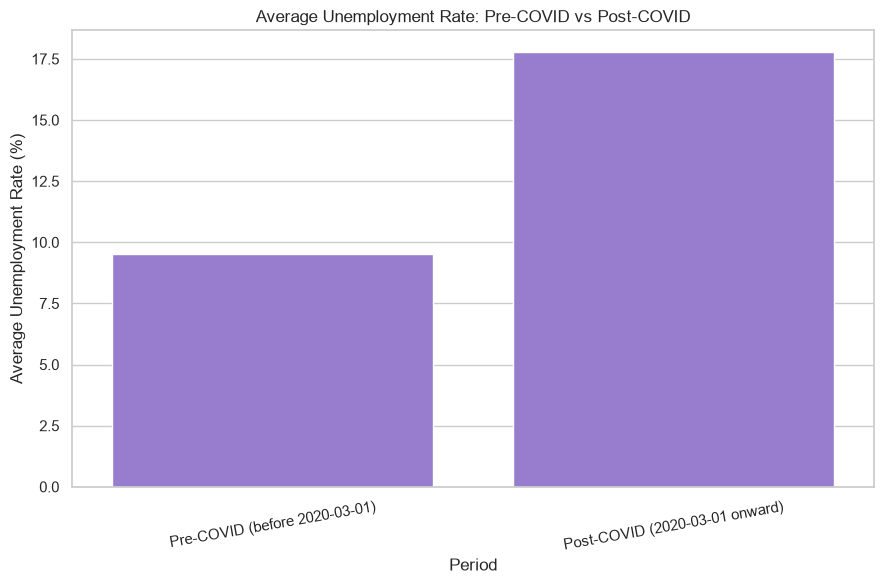

In [11]:
COVID_DATE = pd.Timestamp("2020-03-01")
pre_covid = df[df["Date"] < COVID_DATE]
post_covid = df[df["Date"] >= COVID_DATE]
pre_mean = pre_covid["Estimated Unemployment Rate (%)"].mean()
post_mean = post_covid["Estimated Unemployment Rate (%)"].mean()

comparison = pd.DataFrame({"Period": ["Pre-COVID (before 2020-03-01)", "Post-COVID (2020-03-01 onward)"], "Records": [len(pre_covid), len(post_covid)], "Average Unemployment Rate (%)": [pre_mean, post_mean]})
display(comparison)

print(f"Pre-COVID average: {pre_mean:.2f}%")
print(f"Post-COVID average: {post_mean:.2f}%")
print(f"Difference (Post - Pre): {post_mean - pre_mean:.2f} percentage points")

plt.figure(figsize=(9, 6))
sns.barplot(data=comparison, x="Period", y="Average Unemployment Rate (%)", color="mediumpurple")
plt.title("Average Unemployment Rate: Pre-COVID vs Post-COVID")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Markdown Observation 7 – COVID-19 Comparison
- The analysis uses **1 March 2020** as the split date.
- Pre-COVID records are dated before 1 March 2020; post-COVID records are dated on or after that date.
- The two average unemployment rates provide a simple comparison between the periods.
- The difference is measured in percentage points.
- This is a descriptive comparison; it does not prove that COVID-19 alone caused the change.

## 12. Final Findings

In [12]:
print("FINAL FINDINGS")
print("-" * 60)

highest_region = region_avg.iloc[0]
lowest_region = region_avg.iloc[-1]

print(f"Highest average unemployment region: {highest_region['Region']} " f"({highest_region['Estimated Unemployment Rate (%)']:.2f}%)")
print(f"Lowest average unemployment region: {lowest_region['Region']} " f"({lowest_region['Estimated Unemployment Rate (%)']:.2f}%)")
print(f"Overall average unemployment rate: {df['Estimated Unemployment Rate (%)'].mean():.2f}%")
print(f"Pre-COVID average unemployment rate: {pre_mean:.2f}%")
print(f"Post-COVID average unemployment rate: {post_mean:.2f}%")
print(f"Post-COVID minus Pre-COVID difference: {post_mean - pre_mean:.2f} percentage points")

print("\nDataset period:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Cleaned dataset shape:", df.shape)

FINAL FINDINGS
------------------------------------------------------------
Highest average unemployment region: Tripura (28.35%)
Lowest average unemployment region: Meghalaya (4.80%)
Overall average unemployment rate: 11.79%
Pre-COVID average unemployment rate: 9.51%
Post-COVID average unemployment rate: 17.77%
Post-COVID minus Pre-COVID difference: 8.26 percentage points

Dataset period: 2019-05-31 to 2020-06-30
Cleaned dataset shape: (740, 8)


## 13. Export Cleaned Dataset

In [13]:
OUTPUT_PATH = Path("cleaned_unemployment_data.csv")

try:
    df.to_csv(OUTPUT_PATH, index=False)
    saved_path = OUTPUT_PATH
    print(f"Cleaned dataset exported successfully: {saved_path.resolve()}")
except PermissionError:
    fallback_path = Path("cleaned_unemployment_data_verified.csv")
    df.to_csv(fallback_path, index=False)
    saved_path = fallback_path
    print("The main CSV may be open or locked.")
    print(f"Saved cleaned data to alternative file: {saved_path.resolve()}")

print("Exported shape:", df.shape)

Cleaned dataset exported successfully: E:\LocakDisk C\oasisinfobyte\2.Unemployment_Analysis\cleaned_unemployment_data.csv
Exported shape: (740, 8)


## 14. Final Cleaned Dataset Verification

In [14]:
# Read the exported file again and verify the actual saved CSV
verified_df = pd.read_csv(saved_path)

rows, columns = verified_df.shape
missing_total = int(verified_df.isnull().sum().sum())

print("Dataset File:", saved_path.name)
print("Dataset Shape:", verified_df.shape)
print("Total Rows:", rows)
print("Total Columns:", columns)
print("\nMissing Values by Column:")
display(verified_df.isnull().sum().to_frame("Missing Values"))
print("Total Missing Values:", missing_total)

if rows == 740 and columns == 8 and missing_total == 0:
    print("\nSUCCESS: Cleaned Dataset Verified (740 rows, 8 columns, 0 missing values).")
else:
    print("\nVERIFICATION RESULT: Check the values above. The expected shape may differ if the source CSV has changed.")

display(verified_df.head())

Dataset File: cleaned_unemployment_data.csv
Dataset Shape: (740, 8)
Total Rows: 740
Total Columns: 8

Missing Values by Column:


,Missing Values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0
Month,0


Total Missing Values: 0

SUCCESS: Cleaned Dataset Verified (740 rows, 8 columns, 0 missing values).


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Month
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019-05-01
1,Andhra Pradesh,2019-05-31,Monthly,6.09,4788661.0,37.45,Urban,2019-05-01
2,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,2019-06-01
3,Andhra Pradesh,2019-06-30,Monthly,3.80,4824630.0,36.76,Urban,2019-06-01
4,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,2019-07-01
